# KIỂM TRA GIỮA KỲ — LẬP TRÌNH CHO TRÍ TUỆ NHÂN TẠO VÀ KHOA HỌC DỮ LIỆU
- **Học phần:** 04224 | Mã đề: 01
- **Họ tên:** Hồ Ngọc Anh Thư
- **MSSV:** 2305CT0697
- **Đề tài:** Dự báo học viên ngừng học (Tuần 7-10)

In [31]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
FEATURES = ["gio_tu_hoc_tuan", "ty_le_tham_du", "diem_luyen_tap", "bai_chua_nop"]
CATEGORICAL_FEATURE = "hinh_thuc_hoc"

DATA_DIR = Path(".")
if not (DATA_DIR / "hoc_vien_raw.csv").is_file():
    DATA_DIR = Path("data")
if not (DATA_DIR / "hoc_vien_raw.csv").is_file():
    raise FileNotFoundError("Không tìm thấy tệp hoc_vien_raw.csv!")

print("Python version:", sys.version.split()[0])
print("Pandas:", pd.__version__, "| NumPy:", np.__version__, "| Scikit-learn:", sklearn.__version__)

Python version: 3.13.7
Pandas: 3.0.6 | NumPy: 2.5.3 | Scikit-learn: 1.9.1


### Phần A: Nạp và làm sạch dữ liệu 

In [32]:
# A1: Đọc CSV (giữ dtype ma_hoc_vien là str để không mất số 0 đầu), giữ nguyên df_raw
df_raw = pd.read_csv(DATA_DIR / "hoc_vien_raw.csv", dtype={"ma_hoc_vien": str})
print("Kích thước raw:", df_raw.shape)
print("Kiểu dữ liệu ban đầu:\n", df_raw.dtypes)
print("Số thiếu theo cột:\n", df_raw.isna().sum())

# Sửa lại cách đếm số mã học viên bị lặp theo đúng góp ý
id_counts = df_raw["ma_hoc_vien"].value_counts()
repeated_ids = id_counts[id_counts > 1]
print("Số mã học viên bị lặp:", len(repeated_ids))

dup_count = df_raw.duplicated().sum()
print("Số dòng trùng hoàn toàn:", dup_count)
df_clean = df_raw.drop_duplicates().copy()

df_clean["ma_hoc_vien"] = df_clean["ma_hoc_vien"].str.strip().str.zfill(6)
print("Số mã học viên còn bị lặp sau chuẩn hóa:", df_clean["ma_hoc_vien"].duplicated().sum())

assert df_clean["ma_hoc_vien"].str.fullmatch(r"\d{6}").all()
assert df_clean["ma_hoc_vien"].is_unique
print("Xác nhận: Mã định danh sau khi bỏ trùng là duy nhất và đủ 6 chữ số.")

# A2: Chuyển các cột số sang kiểu số, xử lý giá trị ngoài miền thành NaN
def clean_numeric(series, min_v, max_v, is_int=False):
    s = series.astype(str).str.replace(',', '.', regex=False)
    num = pd.to_numeric(s, errors='coerce')
    if is_int:
        mask_int = num.notna() & (num % 1 == 0)
        num = num.where(mask_int)
    return num.where(num.between(min_v, max_v))

df_clean['gio_tu_hoc_tuan'] = clean_numeric(df_clean['gio_tu_hoc_tuan'], 0, 30)
df_clean['ty_le_tham_du'] = clean_numeric(df_clean['ty_le_tham_du'], 0, 100)
df_clean['diem_luyen_tap'] = clean_numeric(df_clean['diem_luyen_tap'], 0, 10)
df_clean['bai_chua_nop'] = clean_numeric(df_clean['bai_chua_nop'], 0, 8, is_int=True)

valid_hinh_thuc = {'trực tiếp', 'trực tuyến', 'kết hợp'}
df_clean['hinh_thuc_hoc'] = df_clean['hinh_thuc_hoc'].astype(str).str.strip().str.lower()
df_clean['hinh_thuc_hoc'] = df_clean['hinh_thuc_hoc'].where(df_clean['hinh_thuc_hoc'].isin(valid_hinh_thuc), np.nan)

# A3: Xử lý nhãn ngung_hoc và báo cáo chi tiết các bước loại bỏ
initial_rows = len(df_raw)
rows_after_dup = len(df_clean)
dropped_dup = initial_rows - rows_after_dup

df_clean['ngung_hoc'] = pd.to_numeric(df_clean['ngung_hoc'].astype(str).str.replace(',', '.', regex=False), errors='coerce')
valid_label = df_clean['ngung_hoc'].isin([0, 1])
dropped_label = (~valid_label).sum()

df_clean = df_clean[valid_label].copy()
df_clean['ngung_hoc'] = df_clean['ngung_hoc'].astype(int)

print(f"--- BÁO CÁO QUÁ TRÌNH LÀM SẠCH ---")
print(f"1. Số dòng trùng hoàn toàn đã loại: {dropped_dup}")
print(f"2. Số dòng thiếu/sai nhãn ngung_hoc đã loại: {dropped_label}")
print(f"3. Tổng số dòng còn lại sau cùng: {len(df_clean)}")
print(f"Số thiếu cuối cùng theo từng cột đặc trưng:\n{df_clean[FEATURES + [CATEGORICAL_FEATURE]].isna().sum()}")

import os
os.makedirs('data', exist_ok=True)
df_clean.to_csv('data/de01_clean.csv', index=False)
print("Đã lưu tệp data/de01_clean.csv thành công.")

# A4: Chia train / validation / test (60 / 20 / 20) với stratify và random_state = 42
X_all = df_clean[['ma_hoc_vien'] + FEATURES + [CATEGORICAL_FEATURE]].copy()
y_all = df_clean['ngung_hoc'].copy()

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=RANDOM_STATE
)

def thong_ke_tap(ten, y):
    return {
        "Tập": ten,
        "Số hồ sơ": len(y),
        "Số lớp 1": int(y.sum()),
        "Tỷ lệ lớp 1": f"{y.mean():.2%}"
    }

split_summary = pd.DataFrame([
    thong_ke_tap("Train", y_train),
    thong_ke_tap("Validation", y_val),
    thong_ke_tap("Test", y_test)
])
print("\nBảng phân bổ các tập dữ liệu:")
display(split_summary)

# Kiểm tra không giao nhau về mã học viên
assert len(set(X_train['ma_hoc_vien']).intersection(set(X_val['ma_hoc_vien']))) == 0
assert len(set(X_train['ma_hoc_vien']).intersection(set(X_test['ma_hoc_vien']))) == 0
assert len(set(X_val['ma_hoc_vien']).intersection(set(X_test['ma_hoc_vien']))) == 0
print("Xác nhận: Không có sự trùng lặp mã học viên giữa các tập dữ liệu.")

Kích thước raw: (1020, 7)
Kiểu dữ liệu ban đầu:
 ma_hoc_vien            str
gio_tu_hoc_tuan        str
ty_le_tham_du      float64
diem_luyen_tap     float64
bai_chua_nop         int64
hinh_thuc_hoc          str
ngung_hoc          float64
dtype: object
Số thiếu theo cột:
 ma_hoc_vien         0
gio_tu_hoc_tuan    20
ty_le_tham_du       0
diem_luyen_tap     16
bai_chua_nop        0
hinh_thuc_hoc      15
ngung_hoc          10
dtype: int64
Số mã học viên bị lặp: 20
Số dòng trùng hoàn toàn: 20
Số mã học viên còn bị lặp sau chuẩn hóa: 0
Xác nhận: Mã định danh sau khi bỏ trùng là duy nhất và đủ 6 chữ số.
--- BÁO CÁO QUÁ TRÌNH LÀM SẠCH ---
1. Số dòng trùng hoàn toàn đã loại: 20
2. Số dòng thiếu/sai nhãn ngung_hoc đã loại: 10
3. Tổng số dòng còn lại sau cùng: 990
Số thiếu cuối cùng theo từng cột đặc trưng:
gio_tu_hoc_tuan    20
ty_le_tham_du      12
diem_luyen_tap     15
bai_chua_nop        0
hinh_thuc_hoc      15
dtype: int64
Đã lưu tệp data/de01_clean.csv thành công.

Bảng phân bổ các tập dữ l

,Tập,Số hồ sơ,Số lớp 1,Tỷ lệ lớp 1
0,Train,594,161,27.10%
1,Validation,198,54,27.27%
2,Test,198,54,27.27%


Xác nhận: Không có sự trùng lặp mã học viên giữa các tập dữ liệu.


### Phần B: Phân tích và trực quan hóa 

Tỷ lệ lớp 1 toàn train bằng NumPy: 0.2710 (27.1%)
Tỷ lệ lớp 1 toàn train bằng Pandas: 0.2710 (27.1%)

Bảng thống kê theo hình thức học trên train:
hinh_thuc_hoc  Số hồ sơ  Số lớp 1 Tỷ lệ lớp 1
      kết hợp       148        39       26.4%
        thiếu         9         1       11.1%
    trực tiếp       211        53       25.1%
   trực tuyến       226        68       30.1%


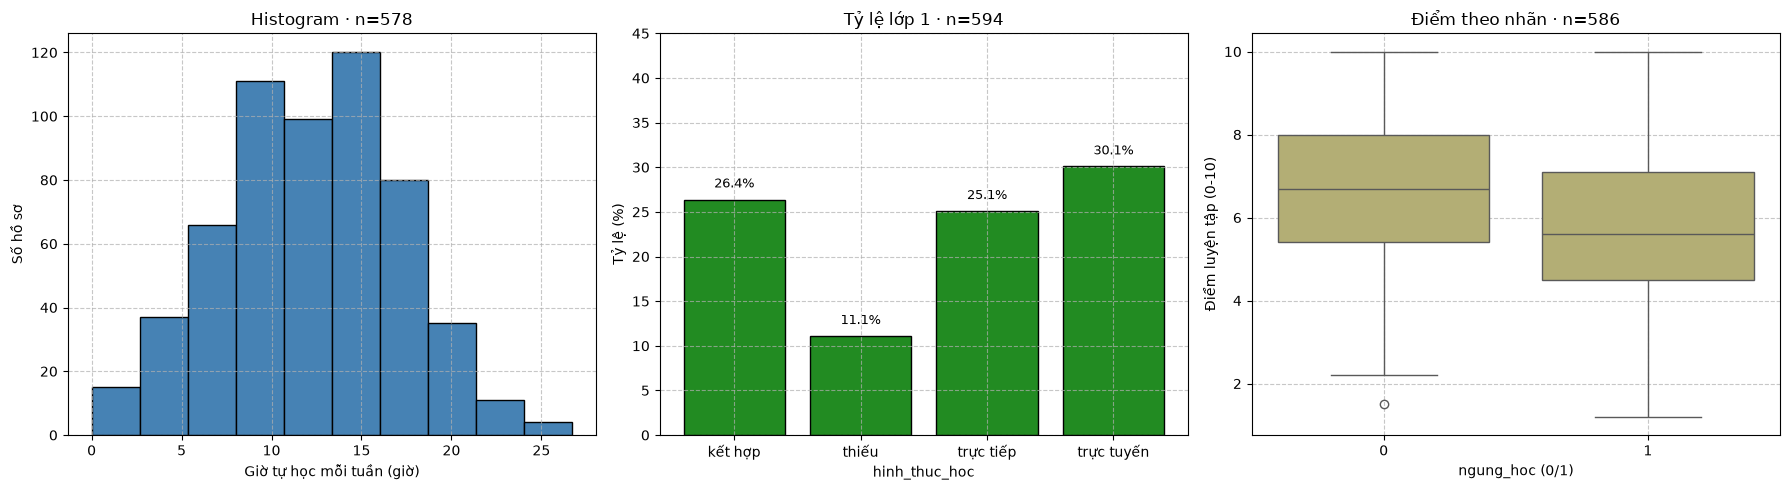

In [33]:
# B1: Tỷ lệ ngung_hoc = 1 trên tập train (đối chiếu NumPy và Pandas)
train_df = X_train.copy()
train_df['ngung_hoc'] = y_train

ratio_numpy = np.mean(y_train)
ratio_pandas = y_train.mean()
print(f"Tỷ lệ lớp 1 toàn train bằng NumPy: {ratio_numpy:.4f} ({ratio_numpy*100:.1f}%)")
print(f"Tỷ lệ lớp 1 toàn train bằng Pandas: {ratio_pandas:.4f} ({ratio_pandas*100:.1f}%)")
assert np.isclose(ratio_numpy, ratio_pandas)

train_df['hinh_thuc_hoc_filled'] = train_df['hinh_thuc_hoc'].fillna('thiếu')
grouped = train_df.groupby('hinh_thuc_hoc_filled', dropna=False).agg(
    so_ho_so=('ngung_hoc', 'count'),
    so_lop_1=('ngung_hoc', 'sum')
).reset_index()
grouped['ty_le_lop_1'] = grouped['so_lop_1'] / grouped['so_ho_so']
grouped.columns = ['hinh_thuc_hoc', 'Số hồ sơ', 'Số lớp 1', 'Tỷ lệ lớp 1']
grouped['Tỷ lệ lớp 1'] = grouped['Tỷ lệ lớp 1'].apply(lambda x: f"{x*100:.1f}%")
print("\nBảng thống kê theo hình thức học trên train:")
print(grouped.to_string(index=False))

# B2: Tạo đúng 3 biểu đồ khám phá từ train (trước khi điền thiếu)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Biểu đồ 1: Histogram giờ tự học (bỏ giá trị thiếu)
gio_data = train_df['gio_tu_hoc_tuan'].dropna()
axes[0].hist(gio_data, bins=10, color='steelblue', edgecolor='black')
axes[0].set_title(f'Histogram · n={len(gio_data)}')
axes[0].set_xlabel('Giờ tự học mỗi tuần (giờ)')
axes[0].set_ylabel('Số hồ sơ')
axes[0].grid(True, linestyle='--', alpha=0.7)

# Biểu đồ 2: Cột tỷ lệ lớp 1 theo hình thức học (đủ n = 594, giữ nhóm thiếu)
axes[1].bar(grouped['hinh_thuc_hoc'], grouped['Số lớp 1'] / grouped['Số hồ sơ'] * 100, color='forestgreen', edgecolor='black')
axes[1].set_title(f'Tỷ lệ lớp 1 · n={len(train_df)}')
axes[1].set_xlabel('hinh_thuc_hoc')
axes[1].set_ylabel('Tỷ lệ (%)')
axes[1].set_ylim(0, 45)
for i, row in grouped.iterrows():
    val = float(row['Tỷ lệ lớp 1'].replace('%',''))
    axes[1].text(i, val + 1, f"{val:.1f}%", ha='center', va='bottom', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.7)

# Biểu đồ 3: Box plot điểm luyện tập theo nhãn 0/1 (bỏ thiếu điểm)
diem_data = train_df[['diem_luyen_tap', 'ngung_hoc']].dropna()
sns.boxplot(x='ngung_hoc', y='diem_luyen_tap', data=diem_data, ax=axes[2], hue='ngung_hoc', palette=['darkkhaki', 'darkkhaki'], legend=False)
axes[2].set_title(f'Điểm theo nhãn · n={len(diem_data)}')
axes[2].set_xlabel('ngung_hoc (0/1)')
axes[2].set_ylabel('Điểm luyện tập (0-10)')
axes[2].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**B3: Phát hiện và nhận xét từ biểu đồ (dựa trên số liệu train thực tế)**
- **Histogram (`gio_tu_hoc_tuan`):** Trung vị giờ tự học là **12.2 giờ**, tính trên 578/594 hồ sơ có giá trị hợp lệ. Phần lớn học viên duy trì thời gian tự học từ 10 đến 18 giờ mỗi tuần.
- **Biểu đồ cột (`hinh_thuc_hoc`):** Nhóm **"trực tuyến"** ghi nhận tỷ lệ ngừng học cao nhất đạt **30.1%** ($68/226$ hồ sơ), cao hơn nhóm kết hợp (26.4%) và trực tiếp (25.1%). Nhóm thiếu dữ liệu có quy mô nhỏ ($n=9$) nên tỷ lệ biến động ($11.1%$) dễ bị ảnh hưởng bởi nhiễu.
- **Box plot (`diem_luyen_tap`):** Trung vị điểm luyện tập của học viên tiếp tục học (lớp 0) là **6.7**, cao hơn mức **5.6** của học viên ngừng học (lớp 1), cho thấy học lực luyện tập có sự khác biệt giữa hai nhóm.
- **Giới hạn:** Do dữ liệu mất cân bằng và có giá trị thiếu, các kết quả trên chỉ mang tính tương quan mô tả từ tập train, tuyệt đối không dùng để khẳng định quan hệ nhân quả hay suy diễn ngoài phạm vi mẫu.

### Phần C: Xây dựng và chọn mô hình 

In [34]:
# C1: Tách tập đặc trưng X (chỉ gồm 4 cột số và 1 cột phân loại, loại bỏ mã học viên và nhãn)
X_train_model = X_train[FEATURES + [CATEGORICAL_FEATURE]]
X_val_model = X_val[FEATURES + [CATEGORICAL_FEATURE]]
X_test_model = X_test[FEATURES + [CATEGORICAL_FEATURE]]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), FEATURES),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), [CATEGORICAL_FEATURE])
    ]
)

# C2, C3: Huấn luyện Baseline, Logistic Regression và Decision Tree
baseline = Pipeline([('prep', preprocessor), ('clf', DummyClassifier(strategy='most_frequent'))])
logreg = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE))])
dt = Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE))])

baseline.fit(X_train_model, y_train)
logreg.fit(X_train_model, y_train)
dt.fit(X_train_model, y_train)

# C4: Lập bảng đánh giá validation cho ba mô hình
def get_metrics(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return {
        'Accuracy': round(accuracy_score(y, y_pred), 4),
        'Precision': round(precision_score(y, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y, y_pred, zero_division=0), 4),
        'ROC AUC': round(roc_auc_score(y, y_proba), 4)
    }

val_summary = pd.DataFrame({
    'Baseline': get_metrics(baseline, X_val_model, y_val),
    'Logistic Regression': get_metrics(logreg, X_val_model, y_val),
    'Decision Tree': get_metrics(dt, X_val_model, y_val)
}).T
print("Bảng đánh giá Validation:")
print(val_summary.to_string())

# C5: Lựa chọn mô hình dựa trên ROC AUC validation chưa làm tròn 
auc_logreg = roc_auc_score(y_val, logreg.predict_proba(X_val_model)[:, 1])
auc_dt = roc_auc_score(y_val, dt.predict_proba(X_val_model)[:, 1])

if auc_logreg >= auc_dt:
    selected_model_name = "Logistic Regression"
    selected_model = logreg
else:
    selected_model_name = "Decision Tree"
    selected_model = dt

print(f"Chọn mô hình: {selected_model_name} với ROC AUC validation cao nhất (LogReg AUC: {auc_logreg:.5f}, DT AUC: {auc_dt:.5f}).")

Bảng đánh giá Validation:
                     Accuracy  Precision  Recall      F1  ROC AUC
Baseline               0.7273     0.0000  0.0000  0.0000   0.5000
Logistic Regression    0.7677     0.6176  0.3889  0.4773   0.7496
Decision Tree          0.7121     0.4400  0.2037  0.2785   0.6180
Chọn mô hình: Logistic Regression với ROC AUC validation cao nhất (LogReg AUC: 0.74961, DT AUC: 0.61799).


### Phần D: Đánh giá và giải thích kết quả 

Bảng đánh giá Test:
                     Accuracy  Precision  Recall      F1  ROC AUC
Baseline               0.7273     0.0000  0.0000  0.0000     0.50
Logistic Regression    0.7879     0.7143  0.3704  0.4878     0.79

Ma trận nhầm lẫn (Hàng: Thực tế, Cột: Dự đoán):
[[136   8]
 [ 34  20]]


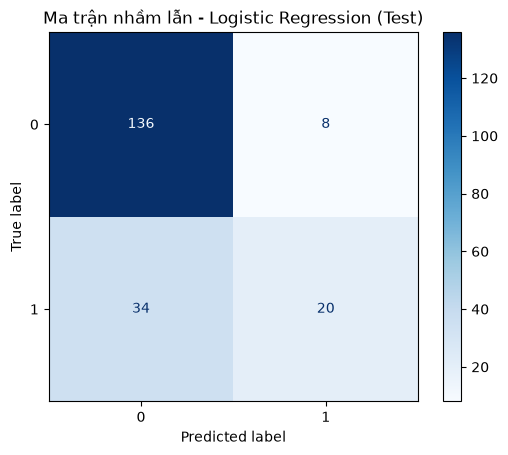

In [35]:
# D1: Đánh giá mô hình đã chọn và baseline trên tập test

def metrics_from_predictions(y_true, y_pred, y_proba):
    return {
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC AUC': round(roc_auc_score(y_true, y_proba), 4)
    }

# Dự đoán mỗi mô hình một lần trên test
y_pred_baseline = baseline.predict(X_test_model)
y_proba_baseline = baseline.predict_proba(X_test_model)[:, 1]

y_pred_selected = selected_model.predict(X_test_model)
y_proba_selected = selected_model.predict_proba(X_test_model)[:, 1]

# Bảng đánh giá
test_summary = pd.DataFrame({
    'Baseline': metrics_from_predictions(
        y_test, y_pred_baseline, y_proba_baseline
    ),
    selected_model_name: metrics_from_predictions(
        y_test, y_pred_selected, y_proba_selected
    )
}).T

print("Bảng đánh giá Test:")
print(test_summary.to_string())

# Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred_selected, labels=[0, 1])

print("\nMa trận nhầm lẫn (Hàng: Thực tế, Cột: Dự đoán):")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Ma trận nhầm lẫn - {selected_model_name} (Test)")
plt.show()

**D2, D3, D4: Giải thích chi tiết và Khuyến nghị (Dựa trên số liệu test thực tế)**

- **D2 (Phân tích ma trận nhầm lẫn & đối chiếu):**
  - Từ ma trận nhầm lẫn `[[136, 8], [34, 20]]` (hàng là thực tế, cột là dự đoán), ta có các giá trị: $TN = 136$, $FP = 8$, $FN = 34$, $TP = 20$ (tổng số mẫu test $n = 198$).
  - **Giải thích:** Có $8$ học viên bị mô hình gắn cờ nhầm là ngừng học ($FP$) dù thực tế các em vẫn tiếp tục học; có $34$ học viên thực sự ngừng học nhưng mô hình bị bỏ sót, không phát hiện kịp thời ($FN$).
  - **Đối chiếu chỉ số từ ma trận:**
    - $\text{Precision} = \frac{TP}{TP + FP} = \frac{20}{20 + 8} = \frac{20}{28} \approx 71.43\%$.
    - $\text{Recall} = \frac{TP}{TP + FN} = \frac{20}{20 + 34} = \frac{20}{54} \approx 37.04\%$.

- **D3 (So sánh với Baseline):**
  - Baseline đạt Accuracy là $0.7273$, nhưng Precision, Recall và F1 đều bằng $0.0$, còn ROC AUC là $0.50$. Độ chính xác cao của Baseline chỉ do tập dữ liệu mất cân bằng (lớp 0 chiếm đa số ~72.7%), bản chất mô hình baseline hoàn toàn **không phát hiện được trường hợp lớp 1 nào**.
  - Logistic Regression cải thiện khả năng phát hiện học viên ngừng học so với baseline, đạt Recall 37.04% và ROC AUC 0.79. Tuy nhiên, mô hình vẫn bỏ sót 34 trường hợp thực sự ngừng học, do đó khả năng phát hiện lớp 1 vẫn còn hạn chế.

- **D4 (Khuyến nghị 5-7 câu dựa trên số liệu):**
1. Tôi lựa chọn Logistic Regression vì mô hình đạt ROC AUC validation 0.7496, cao hơn Decision Tree (0.6180); trên tập test, mô hình đạt Accuracy 78.79% và ROC AUC 0.7900.
2. Mô hình có Precision 71.43% với 8 trường hợp cảnh báo nhầm (FP), nhưng Recall chỉ đạt 37.04% và bỏ sót 34 học viên thực sự ngừng học (FN), cho thấy vẫn cần cải thiện khả năng phát hiện học viên có nguy cơ.
3. Vì dữ liệu chỉ là dữ liệu mô phỏng, có giá trị thiếu và mất cân bằng lớp, kết quả chưa thể đại diện đầy đủ cho hành vi của học viên trong môi trường đào tạo thực tế.
4. Một cải tiến cần kiểm chứng là bổ sung dữ liệu chuyên cần và tình hình nộp bài theo từng tuần, đồng thời lựa chọn ngưỡng cảnh báo phù hợp bằng tập validation và đánh giá lại trên một đợt học viên mới.
5. Không được sử dụng tập test để điều chỉnh mô hình hoặc ngưỡng dự đoán vì sẽ làm mất tính độc lập của tập đánh giá và khiến kết quả đo lường không còn khách quan.